# Food-101 by Matyas Andrys

Training CNN on [Food-101 dataset on Kaggle](https://www.kaggle.com/datasets/ranitsarkar01/the-food-101-data-set) to classify food images.

You know... I'm hungry.

## Install and setup dependencies

In [ ]:
%pip install -q kagglehub matplotlib torch torchvision seaborn numpy pandas pillow scikit-learn

In [38]:
from pathlib import Path

import kagglehub as kaggle
from PIL import Image, ImageOps
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import Subset, Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

In [3]:
SEED = 42 # The meaning of life

np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style='whitegrid')

def get_best_device():
    if torch.cuda.is_available():
        return 'cuda'
    if torch.backends.mps.is_available():
        return 'mps'
    return 'cpu'

device = torch.device(get_best_device())
print('torch version:', torch.__version__)
print('device:', device)

torch version: 2.14.1
device: mps


## Download the dataset

Use KaggleHub to download the dataset and then load it.

In [4]:
images_root = Path(kaggle.dataset_download('ranitsarkar01/the-food-101-data-set')) / 'food-101' / 'images'
full_dataset = datasets.ImageFolder(images_root)

## Exploration analysis

Let's look at the image dataset, mainly image sizes, color mode, and class distribution.

In [5]:
def print_dataset_info(dataset: datasets.ImageFolder):
    rows = []

    # Load images directly from files to retrieve metadata only and avoid loading full images
    for image_path, label in dataset.samples:
        with Image.open(image_path) as image:
            rows.append({
                'width': image.width,
                'height': image.height,
                'label': dataset.classes[label],
                'mode': image.mode
            })

    data = pd.DataFrame(rows)
    display(data.describe())
    display(data.groupby('label').size().reset_index(name='image_count_per_class').describe())
    display(
        data.groupby('mode').size().to_frame('image_count')
        .sort_values('image_count', ascending=False)
    )

print_dataset_info(full_dataset)

,width,height
count,101000.000000,101000.000000
mean,495.791396,475.372129
std,45.674348,65.305769
min,193.000000,122.000000
25%,512.000000,452.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,512.000000,512.000000


,image_count_per_class
count,101.0
mean,1000.0
std,0.0
min,1000.0
25%,1000.0
50%,1000.0
75%,1000.0
max,1000.0


,image_count
mode,
RGB,100997
L,3


As we can see, the dataset contains images of various sizes, mostly of 512 x 512.
Width ranges from **193px** to **512px**. Height ranges from **122px** to **512px**.
The most common mode is **RGB**, which is expected for color images. Three images are in **grayscale**.
The distribution of classes is consistent, with **1000** images per class and **101** classes. Total is **101000** images.

## Preparing data split indices

Before continuing, we need to prepare the data split indices. We will reuse already provided train and test indices,
with addition of the train indices being split into **10%** validation set and **90%** train set.

In [8]:
id_to_index = {
    Path(image_path).relative_to(images_root).with_suffix("").as_posix(): index
    for index, (image_path, _) in enumerate(full_dataset.samples)
}

def parse_ids(path: Path) -> list[int]:
    return [id_to_index[image_id] for image_id in path.read_text().splitlines()]

train_indices = parse_ids(images_root.parent / 'meta' / 'train.txt')
test_indices =  parse_ids(images_root.parent / 'meta' / 'test.txt')

train_indices, valid_indices = train_test_split(
    train_indices,
    test_size=0.1,
    random_state=SEED,
    stratify=[full_dataset.targets[index] for index in train_indices],
)

print(f"Train indices: {len(train_indices)}")
print(f"Validation indices: {len(valid_indices)}")
print(f"Test indices: {len(test_indices)}")

Train indices: 68175
Validation indices: 7575
Test indices: 25250


## Image normalization

We will need to normalize the images before training.

First we need to scale the images to a consistent size. We will use **224 x 224** pixels as the target size.
We will scale the longest side of the image to **224** pixels and pad the shorter side with the **mean value** of the dataset.

To get the **mean** value and **standard deviation** used for **padding** and **normalization**,
we will calculate it from the training dataset.

In [15]:
stats_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")), # Convert all images to RGB
    transforms.ToTensor(),
])

stats_dataset = Subset(
    datasets.ImageFolder(images_root, transform=stats_transform),
    train_indices
)

def calculate_mean_std(dataset: Dataset):
    channel_sum = torch.zeros(3)
    channel_squared_sum = torch.zeros(3)
    pixel_count = 0

    for image, _ in dataset:
        channel_sum += image.sum(dim=(1, 2)) # Sum of read, green and blue channels
        channel_squared_sum += (image ** 2).sum(dim=(1, 2))
        pixel_count += image.shape[1] * image.shape[2]

    mean = channel_sum / pixel_count
    std = (channel_squared_sum / pixel_count - mean ** 2).sqrt() # E(x^2) - E(x)^2

    return mean, std

train_mean, train_std = calculate_mean_std(stats_dataset)

print(f"Mean: {train_mean.tolist()}")
print(f"Std: {train_std.tolist()}")

Mean: [0.5495780110359192, 0.44518497586250305, 0.3437715768814087]
Std: [0.2727675139904022, 0.27580633759498596, 0.2799089252948761]


Now we can use the calculated mean and standard deviation to perform image padding.
Normalization is defined as `(value - mean) / std`, we can use this knowledge to fill the padded area
with the value which will after normalization be **close to zero**.

In [29]:
def resize_and_pad(image: Image.Image, size, fill):
    width, height = image.size
    scale = size / max(width, height) # Calculate scaling factor

    # Resize image so that the longest side is of length `size`
    new_width = round(width * scale)
    new_height = round(height * scale)
    image = image.resize((new_width, new_height))

    # Calculate padding values
    left = (size - new_width) // 2
    top = (size - new_height) // 2
    right = size - new_width - left
    bottom = size - new_height - top

    # Fill padded area with `fill` color
    return ImageOps.expand(image, border=(left, top, right, bottom), fill=fill)

Let's define our **image transformations pipeline** for train, test and validation.

All transformations are identical, since they all only perform resizing, padding and normalization.
This will be used as baseline for future data augmentation experiments.

In [36]:
IMAGE_SIZE = 224 # Out defined image size
pad_fill = tuple((train_mean * 255).round().int().tolist()) # Mean
normalize = transforms.Normalize(mean=train_mean, std=train_std)

#transforms.RandomHorizontalFlip(),
#transforms.ColorJitter(
#    brightness=0.2,
#    contrast=0.2,
#    saturation=0.2,
#),

train_transform = test_transform = valid_transform = transforms.Compose([
    transforms.Lambda(lambda image: image.convert("RGB")), # Convert all images to RGB
    transforms.Lambda(lambda image: resize_and_pad(image, IMAGE_SIZE, pad_fill)),
    transforms.ToTensor(),
    normalize
])

## Data loading

We can now define our **data loaders** with our transformations. Batch size is set to **64**.
Train loader is **shuffled** to prevent overfitting on a single batch.

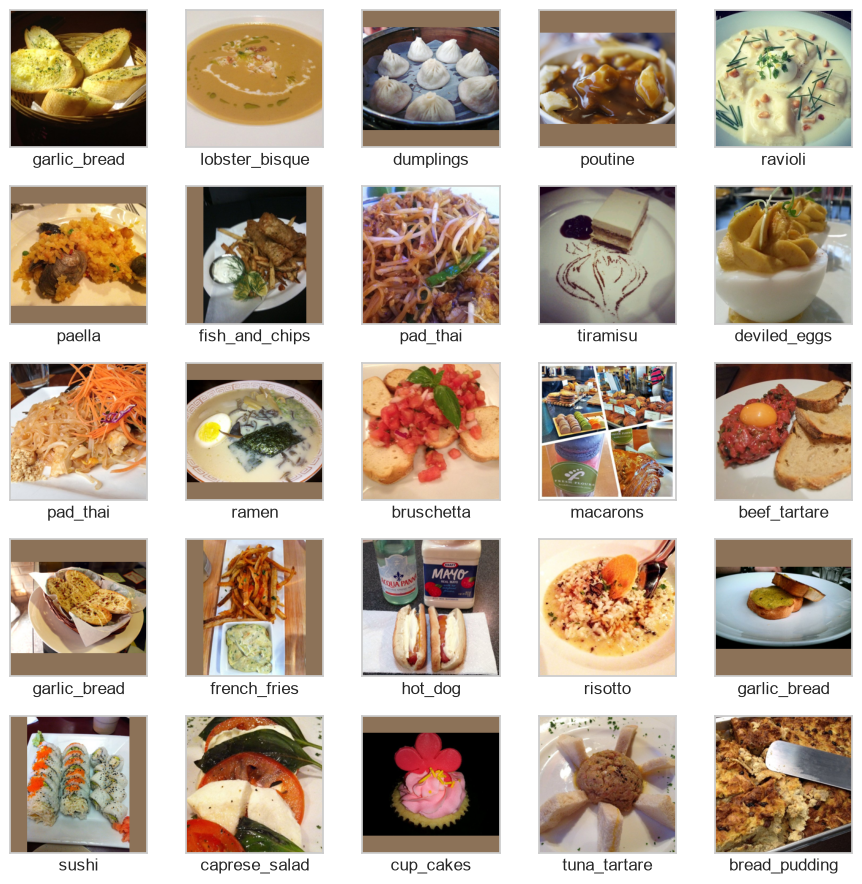

In [39]:
BATCH_SIZE = 64

train_dataset = Subset(datasets.ImageFolder(images_root, transform=train_transform), train_indices)
valid_dataset = Subset(datasets.ImageFolder(images_root, transform=valid_transform), valid_indices)
test_dataset = Subset(datasets.ImageFolder(images_root, transform=test_transform), test_indices)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

def display_sample(loader: DataLoader):
    # Dimension [3] to [3, 1, 1], allowing multiplication with tensor image
    mean = train_mean.view(3, 1, 1)
    std = train_std.view(3, 1, 1)

    images, labels = next(iter(loader))

    plt.figure(figsize=(9, 9))
    for i in range(25):
        image = (images[i] * std + mean).clamp(0, 1) # Undo normalization to correctly display colors

        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(image.permute(1, 2, 0)) # Reorder [C, H, W] to [H, W, C], aka what Matplotlib expects
        plt.xlabel(full_dataset.classes[labels[i]])

    plt.tight_layout()
    plt.show()

display_sample(train_loader)